# Session 26 Solutions: Gradient Boosting

Data Science with Python, Level 2, Stage 4: Applied ML

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import (GradientBoostingRegressor, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor, RandomForestClassifier)
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import roc_auc_score, r2_score, mean_absolute_error

DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
churn["left"] = (churn["churn"] == "Yes").astype(int)
churn["monthly_contract"] = (churn["contract"] == "Month-to-month").astype(int)
churn["fiber"] = (churn["internet"] == "Fiber").astype(int)
churn["echeck"] = (churn["payment_method"] == "Electronic check").astype(int)
features = ["tenure_months", "monthly_charges", "support_calls", "senior",
            "monthly_contract", "fiber", "echeck"]
X_train, X_test, y_train, y_test = train_test_split(
    churn[features].astype(float), churn["left"],
    test_size=0.25, random_state=42, stratify=churn["left"])

## In-Class Exercises

### In-Class Exercise 1: Learning Curve Chart

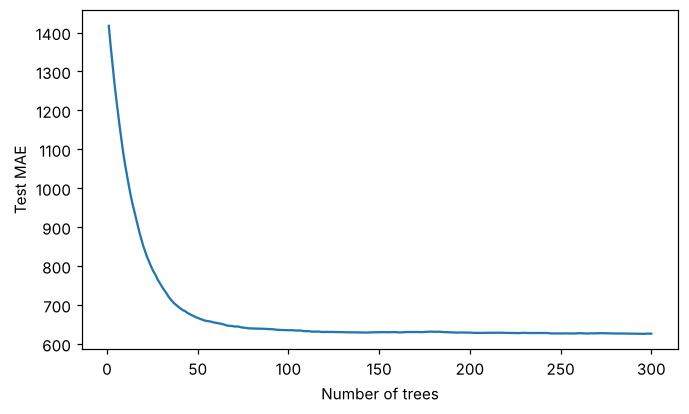

In [2]:
cols = ["temp_c", "humidity", "wind_kmh", "working_day", "holiday"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(bikes[cols].astype(float), bikes["rentals"], test_size=0.25, random_state=0)
boost = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=0).fit(Xb_train, yb_train)
mae = [mean_absolute_error(yb_test, p) for p in boost.staged_predict(Xb_test)]
plt.plot(range(1, 301), mae)
plt.xlabel("Number of trees")
plt.ylabel("Test MAE")
plt.show()

### In-Class Exercise 2: Learning Rate Race

In [3]:
cols = ["temp_c", "humidity", "wind_kmh", "working_day", "holiday"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(bikes[cols].astype(float), bikes["rentals"], test_size=0.25, random_state=0)
for lr in [0.01, 0.1, 0.5]:
    g = GradientBoostingRegressor(n_estimators=300, learning_rate=lr, max_depth=3, random_state=0).fit(Xb_train, yb_train)
    print(lr, round(r2_score(yb_test, g.predict(Xb_test)), 3))

0.01 0.774
0.1 0.778
0.5 0.68


### In-Class Exercise 3: Three Models, One Table

In [4]:
models = {
    "forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=0, n_jobs=-1),
    "boost default": HistGradientBoostingClassifier(random_state=0),
    "boost shallow": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=150, random_state=0),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(name, round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 3))

forest 0.808
boost default 0.756
boost shallow 0.802


### In-Class Exercise 4: Missing Values Welcome

In [5]:
cols = ["tenure_months", "monthly_charges", "total_charges", "support_calls"]
print(churn[cols].isna().sum().sum())
m = HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, random_state=0)
print(cross_val_score(m, churn[cols], churn["left"], cv=5, scoring="roc_auc").mean().round(3))

11
0.724


## Part A: Basic

### Exercise 1: Residuals by Hand

This is exactly one boosting step with a learning rate of 0.5. Repeating it hundreds of times is gradient boosting.

In [6]:
from sklearn.tree import DecisionTreeRegressor
Xt = bikes[["temp_c"]]
yt = bikes["rentals"]
start = np.full(len(yt), yt.mean())
residual = yt - start
tree = DecisionTreeRegressor(max_depth=2).fit(Xt, residual)
after = start + 0.5 * tree.predict(Xt)
print(round(mean_absolute_error(yt, start)), round(mean_absolute_error(yt, after)))

1363 1041


### Exercise 2: Counting Trees

In [7]:
for lr in [0.2, 0.05, 0.01]:
    m = HistGradientBoostingClassifier(learning_rate=lr, max_iter=2000, early_stopping=True, n_iter_no_change=20, random_state=0).fit(X_train, y_train)
    print(lr, m.n_iter_, round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 3))

0.2 32 0.756
0.05 56 0.782
0.01 193 0.791


## Part B: Intermediate

### Exercise 3: Apartment Prices with Boosting

In [8]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
cols = ["district", "area_m2", "rooms", "floor", "building_age", "distance_center_km", "elevator", "parking"]
Xa = flats[cols].copy()
Xa["district"] = Xa["district"].astype("category")
Xa[["elevator", "parking"]] = Xa[["elevator", "parking"]].astype(int)
m = HistGradientBoostingRegressor(categorical_features="from_dtype", learning_rate=0.05, random_state=0)
folds = KFold(5, shuffle=True, random_state=0)
print(cross_val_score(m, Xa, flats["price_k"], cv=folds, scoring="r2").mean().round(3))
print(-cross_val_score(m, Xa, flats["price_k"], cv=folds, scoring="neg_mean_absolute_error").mean().round(1))

0.749
9.9


### Exercise 4: Exam Scores Model

In [9]:
from sklearn.linear_model import LinearRegression
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
Xe = exams[["class", "study_hours_week", "sleep_hours", "attendance_pct"]].copy()
Xe["class"] = Xe["class"].astype("category")
folds = KFold(5, shuffle=True, random_state=0)
hgb = HistGradientBoostingRegressor(categorical_features="from_dtype", learning_rate=0.05, max_depth=3, random_state=0)
print("boost", cross_val_score(hgb, Xe, exams["math"], cv=folds).mean().round(3))
print("linear", cross_val_score(LinearRegression(), Xe.drop(columns="class"), exams["math"], cv=folds).mean().round(3))

boost 0.2
linear 0.25


## Part C: Challenge

### Exercise 5: Time-Aware Validation

In [10]:
bikes["date"] = pd.to_datetime(bikes["date"])
Xc = bikes[["season", "weather", "temp_c", "humidity", "wind_kmh", "working_day", "holiday"]].copy()
Xc["season"] = Xc["season"].astype("category")
Xc["weather"] = Xc["weather"].astype("category")
Xc[["working_day", "holiday"]] = Xc[["working_day", "holiday"]].astype(int)
first = bikes["date"].dt.year == 2023
m = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=0).fit(Xc[first], bikes.loc[first, "rentals"])
print(round(r2_score(bikes.loc[~first, "rentals"], m.predict(Xc[~first])), 3))
# If rentals grow from one year to the next, a model trained on 2023 under-predicts 2024.
# Shuffled folds hide this, because every fold contains days from both years.

0.647


## Part D: Cumulative Project: Customer Churn

### Exercise 6: Customer Churn: Step 3, Boosting

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
data = pd.read_csv(DATA_URL + "telecom_churn.csv")
y = (data["churn"] == "Yes").astype(int)
X = data.drop(columns=["customer_id", "churn"])
X_dev, X_final, y_dev, y_final = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
num_cols = ["tenure_months", "monthly_charges", "total_charges", "support_calls"]
cat_cols = ["gender", "contract", "internet", "payment_method"]
bool_cols = ["senior", "paperless_billing"]
def preprocess():
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore")), cat_cols),
        ("bool", "passthrough", bool_cols),
    ])
models = {
    "logistic": LogisticRegression(max_iter=1000),
    "forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=0, n_jobs=-1),
    "boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=200, random_state=0),
}
rows = []
for name, est in models.items():
    s = cross_val_score(make_pipeline(preprocess(), est), X_dev, y_dev, cv=5, scoring="roc_auc")
    rows.append({"model": name, "mean_auc": s.mean().round(3), "std": s.std().round(3)})
pd.DataFrame(rows).sort_values("mean_auc", ascending=False)

,model,mean_auc,std
0,logistic,0.786,0.013
1,forest,0.774,0.020
2,boosting,0.763,0.016


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Boosting is sequential. |
| 2 | B | Each tree corrects less, so more are needed. |
| 3 | B | It watches a validation set. |
| 4 | B | A large gap between train and test. |
| 5 | B | Unshuffled folds follow the date order. |